In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("customers.csv")

In [4]:
df.head()

,CustomerID,Age,Annual Income,Spending Score
0,C0001,23,87726,92
1,C0002,26,18860,28
2,C0003,41,61435,100
3,C0004,38,111119,74
4,C0005,33,121280,81


In [5]:
features = ["Age","Annual Income", "Spending Score"]

In [6]:
#features
X = df[features].dropna()

In [7]:
X

,Age,Annual Income,Spending Score
0,23,87726,92
1,26,18860,28
2,41,61435,100
3,38,111119,74
4,33,121280,81
...,...,...,...
495,39,46183,74
496,19,21473,29
497,44,109462,62
498,39,103588,24


In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()


In [9]:
X_scaled = scaler.fit_transform(X)

In [10]:
from sklearn.cluster import KMeans

In [11]:
wcss = []

k_values = range(1,11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init= 10,
        random_state=1
    )

    model.fit(X_scaled)
    wcss.append(model.inertia_)

In [12]:
wcss

[1500.0,
 918.9586927456927,
 574.2184703505378,
 446.62457296706157,
 365.16444956608666,
 330.620297283765,
 297.23901950443644,
 266.7356488109761,
 242.71113493665752,
 230.51724070387826]

Text(0.5, 1.0, 'Elbow Method of optimal K')

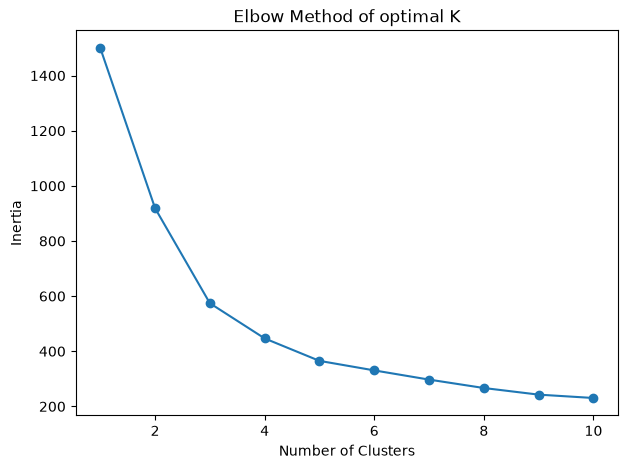

In [14]:
plt.figure(figsize=(7,5))

plt.plot(
    k_values,
    wcss,
    marker='o',
    linestyle='-'
)

plt.xlabel("Number of Clusters")
plt.ylabel("Inertia"),
plt.title("Elbow Method of optimal K")



In [25]:
#fit the final model
optimal_k = 5

final_model = KMeans(
    n_clusters= optimal_k,
    init="k-means++",
    n_init=10,
    random_state=1
)

In [26]:
labels = final_model.fit_predict(X_scaled)

In [27]:
labels

array([2, 1, 2, 0, 0, 4, 3, 4, 0, 0, 2, 4, 4, 0, 4, 1, 2, 4, 2, 1, 4, 0,
       2, 1, 3, 0, 3, 4, 4, 1, 0, 0, 4, 2, 2, 1, 1, 4, 4, 0, 3, 2, 0, 3,
       2, 4, 2, 3, 1, 3, 2, 3, 1, 0, 3, 4, 1, 2, 0, 0, 0, 0, 0, 4, 2, 3,
       0, 4, 4, 4, 0, 4, 2, 2, 2, 1, 2, 2, 2, 1, 0, 4, 4, 0, 4, 0, 4, 2,
       3, 2, 3, 2, 3, 1, 3, 2, 2, 2, 1, 1, 0, 3, 3, 0, 4, 0, 3, 3, 3, 0,
       2, 3, 0, 1, 4, 1, 3, 3, 1, 4, 0, 3, 2, 4, 1, 3, 3, 0, 2, 2, 1, 4,
       2, 2, 2, 1, 1, 4, 0, 4, 0, 1, 3, 2, 0, 2, 4, 3, 2, 1, 2, 4, 1, 1,
       2, 0, 4, 0, 2, 0, 3, 4, 3, 0, 4, 3, 1, 4, 0, 3, 2, 2, 0, 2, 4, 0,
       4, 2, 3, 1, 2, 1, 0, 4, 0, 4, 4, 3, 2, 2, 2, 0, 2, 2, 3, 4, 3, 1,
       0, 4, 2, 1, 4, 1, 0, 4, 0, 4, 1, 4, 4, 2, 1, 4, 1, 4, 4, 3, 0, 0,
       3, 0, 4, 4, 1, 3, 3, 0, 1, 2, 1, 0, 4, 2, 4, 1, 0, 3, 1, 3, 4, 1,
       3, 0, 1, 4, 3, 4, 0, 1, 3, 4, 0, 1, 0, 2, 3, 3, 1, 2, 3, 1, 2, 2,
       4, 3, 4, 0, 1, 0, 1, 4, 2, 4, 1, 2, 1, 4, 4, 4, 2, 4, 1, 0, 0, 3,
       3, 0, 1, 2, 3, 2, 4, 4, 1, 3, 3, 3, 4, 2, 2,

In [28]:
df_clustered= df.loc[X.index].copy()
df_clustered["Cluster"] = labels

In [29]:
df_clustered

,CustomerID,Age,Annual Income,Spending Score,Cluster
0,C0001,23,87726,92,2
1,C0002,26,18860,28,1
2,C0003,41,61435,100,2
3,C0004,38,111119,74,0
4,C0005,33,121280,81,0
...,...,...,...,...,...
495,C0496,39,46183,74,4
496,C0497,19,21473,29,1
497,C0498,44,109462,62,0
498,C0499,39,103588,24,3


In [30]:
from sklearn.metrics import silhouette_score

In [31]:
silhouette_score(X_scaled, labels)

0.3691659303238332

In [32]:
df_clustered.groupby("Cluster")[features].mean()

,Age,Annual Income,Spending Score
Cluster,,,
0,42.000000,106768.064516,80.602151
1,24.835052,29645.597938,25.072165
2,26.550847,69804.822034,82.483051
3,51.719101,119817.921348,25.707865
4,36.271845,55061.485437,51.990291


Text(0.5, 1.0, 'Customer Segmentation using K-Means')

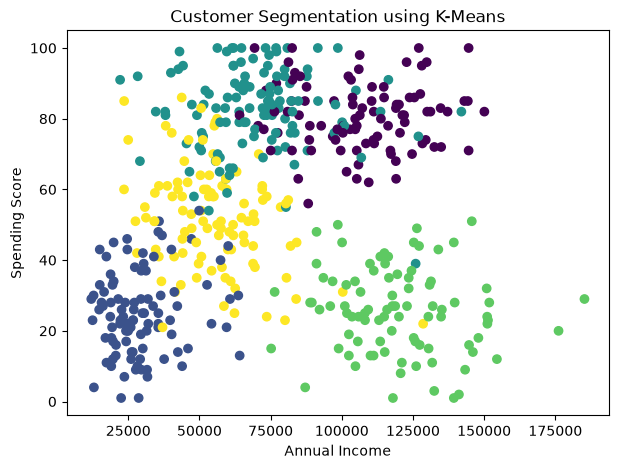

In [33]:
plt.figure(figsize=(7,5))

plt.scatter(
    df_clustered["Annual Income"],
    df_clustered["Spending Score"],
    c= labels,
    cmap="viridis"
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Customer Segmentation using K-Means")